In [1]:
%pip install pandas scikit-learn matplotlib ucimlrepo


Note: you may need to restart the kernel to use updated packages.


## 1단계: 데이터 불러오기 (Statlog German Credit)

UCI 머신러닝 저장소의 `ucimlrepo` 패키지로 **German Credit** 데이터(id=144)를 가져온다.

- `fetch_ucirepo(id=144)`가 돌려주는 객체 안에
  - `data.features` → 신청자 정보 20개 컬럼 (X)
  - `data.targets` → 정답 컬럼 `class` (y)
  - `variables` → 각 컬럼의 설명표 (다음 단계에서 이름 바꿀 때 사용)
- 확인할 것: 행이 **1,000개**, 속성이 **20개**인지, 그리고 `class` 값이 몇 개씩 있는지 (good 700 / bad 300 이어야 함).

> 처음 실행할 때는 인터넷에서 내려받으니 몇 초 걸릴 수 있다.

In [2]:
import pandas as pd
from ucimlrepo import fetch_ucirepo

german = fetch_ucirepo(id=144)

X = german.data.features   # 신청자 정보 (20개 컬럼)
y = german.data.targets    # 정답 (class 컬럼 1개)

print("X 크기:", X.shape)   # (1000, 20) 이어야 함
print("y 크기:", y.shape)   # (1000, 1) 이어야 함
print()
print("class 값별 인원수:")
print(y["class"].value_counts())

X.head()

X 크기: (1000, 20)
y 크기: (1000, 1)

class 값별 인원수:
class
1    700
2    300
Name: count, dtype: int64


,Attribute1,Attribute2,Attribute3,Attribute4,Attribute5,Attribute6,Attribute7,Attribute8,Attribute9,Attribute10,Attribute11,Attribute12,Attribute13,Attribute14,Attribute15,Attribute16,Attribute17,Attribute18,Attribute19,Attribute20
0,A11,6,A34,A43,1169,A65,A75,4,A93,A101,4,A121,67,A143,A152,2,A173,1,A192,A201
1,A12,48,A32,A43,5951,A61,A73,2,A92,A101,2,A121,22,A143,A152,1,A173,1,A191,A201
2,A14,12,A34,A46,2096,A61,A74,2,A93,A101,3,A121,49,A143,A152,1,A172,2,A191,A201
3,A11,42,A32,A42,7882,A61,A74,2,A93,A103,4,A122,45,A143,A153,1,A173,2,A191,A201
4,A11,24,A33,A40,4870,A61,A73,3,A93,A101,4,A124,53,A143,A153,2,A173,2,A191,A201


## 2-1단계: 컬럼 이름을 읽기 쉽게 바꾸기

`Attribute1`, `Attribute2` 같은 이름은 무슨 뜻인지 알 수 없다. 
`german.variables` 설명표의 `description`을 보고, 각 컬럼에 짧은 영어 이름을 붙인다.

- 딕셔너리 `{옛 이름: 새 이름}`을 만들고 `X.rename(columns=...)`로 바꾼다.
- 가장 중요한 것: **`Attribute13` → `age`** (나이, 단위: 년). 이번 공정성 감사의 핵심 컬럼이다.
- 마지막에 설명표와 새 이름을 나란히 출력해서 하나씩 맞게 붙었는지 눈으로 확인한다.

In [3]:
new_names = {
    "Attribute1":  "checking_status",          # 당좌예금 계좌 상태
    "Attribute2":  "duration_months",          # 대출 기간 (개월)
    "Attribute3":  "credit_history",           # 과거 신용 기록
    "Attribute4":  "purpose",                  # 대출 목적
    "Attribute5":  "credit_amount",            # 대출 금액 (DM, 독일 마르크)
    "Attribute6":  "savings",                  # 저축 계좌 / 채권
    "Attribute7":  "employment_since",         # 현재 직장 근무 기간
    "Attribute8":  "installment_rate",         # 가처분소득 대비 할부금 비율 (1~4)
    "Attribute9":  "personal_status_sex",      # 결혼 상태 + 성별
    "Attribute10": "other_debtors",            # 공동 채무자 / 보증인
    "Attribute11": "residence_since",          # 현재 집 거주 기간 (1~4)
    "Attribute12": "property",                 # 보유 재산
    "Attribute13": "age",                      # 나이 (년)  ← 감사 대상
    "Attribute14": "other_installment_plans",  # 다른 할부 계획
    "Attribute15": "housing",                  # 주거 형태
    "Attribute16": "existing_credits",         # 이 은행의 기존 대출 수
    "Attribute17": "job",                      # 직업
    "Attribute18": "num_dependents",           # 부양 책임 인원 수
    "Attribute19": "telephone",                # 전화 등록 여부
    "Attribute20": "foreign_worker",           # 외국인 노동자 여부
}

X = X.rename(columns=new_names)

# 확인: 원래 설명과 새 이름을 나란히 놓고 보기
check = german.variables[["name", "description", "type"]].copy()
check["new_name"] = check["name"].map(new_names)
check

,name,description,type,new_name
0,Attribute1,Status of existing checking account,Categorical,checking_status
1,Attribute2,Duration,Integer,duration_months
2,Attribute3,Credit history,Categorical,credit_history
3,Attribute4,Purpose,Categorical,purpose
4,Attribute5,Credit amount,Integer,credit_amount
5,Attribute6,Savings account/bonds,Categorical,savings
6,Attribute7,Present employment since,Categorical,employment_since
7,Attribute8,Installment rate in percentage of disposable i...,Integer,installment_rate
8,Attribute9,Personal status and sex,Categorical,personal_status_sex
9,Attribute10,Other debtors / guarantors,Categorical,other_debtors


## 2-2단계: 코드값(A11 등)의 뜻을 표로 정리

범주형 컬럼의 값은 `A11`, `A34`처럼 코드로 되어 있다. 코드의 뜻은 데이터 안에 없고, UCI 데이터 페이지의 원본 설명 문서(`german.doc`)에만 있다. 그래서 그 문서를 보고 직접 표로 옮긴다.

- 각 줄 = (컬럼, 코드, 원문 설명 `meaning_en`, 한국어 뜻)
- 금액 단위 **DM** = 독일 마르크 (1994년에 UCI에 공개된 독일 은행 자료)
- `count` 컬럼: 실제 데이터에서 그 코드를 가진 사람이 몇 명인지 센 값. **0이면 문서에는 있지만 데이터에는 없는 코드**다.
  - `A47` (휴가): 문서에만 있고 데이터에는 0명
  - `A95` (미혼 여성): 문서에만 있고 데이터에는 0명 → 그래서 `personal_status_sex`로는 미혼 여성과 다른 여성을 구분할 수 없다 (발표 때 데이터 한계로 언급할 만함)
- 마지막 줄은 표에 빠진 코드가 없는지 확인한다. **"빠진 코드: 없음"이 나와야 정상.**

In [4]:
# (컬럼, 코드, 원문 설명, 한국어 뜻) — 출처: UCI german.doc
codes = [
    ("checking_status", "A11", "... < 0 DM", "잔고 0 DM 미만 (마이너스)"),
    ("checking_status", "A12", "0 <= ... < 200 DM", "잔고 0 이상 200 DM 미만"),
    ("checking_status", "A13", "... >= 200 DM / salary assignments for at least 1 year", "잔고 200 DM 이상 또는 1년 이상 급여 이체"),
    ("checking_status", "A14", "no checking account", "당좌 계좌 없음"),

    ("credit_history", "A30", "no credits taken / all credits paid back duly", "대출 없음 / 모두 제때 상환"),
    ("credit_history", "A31", "all credits at this bank paid back duly", "이 은행 대출 모두 제때 상환"),
    ("credit_history", "A32", "existing credits paid back duly till now", "현재 대출을 지금까지 제때 상환 중"),
    ("credit_history", "A33", "delay in paying off in the past", "과거 상환 연체 있음"),
    ("credit_history", "A34", "critical account / other credits existing (not at this bank)", "위험 계좌 / 다른 은행에 대출 있음"),

    ("purpose", "A40", "car (new)", "새 차"),
    ("purpose", "A41", "car (used)", "중고차"),
    ("purpose", "A42", "furniture/equipment", "가구/장비"),
    ("purpose", "A43", "radio/television", "라디오/TV"),
    ("purpose", "A44", "domestic appliances", "가전제품"),
    ("purpose", "A45", "repairs", "수리"),
    ("purpose", "A46", "education", "교육"),
    ("purpose", "A47", "(vacation - does not exist?)", "휴가 (데이터에 없음)"),
    ("purpose", "A48", "retraining", "재교육/직업훈련"),
    ("purpose", "A49", "business", "사업"),
    ("purpose", "A410", "others", "기타"),

    ("savings", "A61", "... < 100 DM", "100 DM 미만"),
    ("savings", "A62", "100 <= ... < 500 DM", "100 이상 500 DM 미만"),
    ("savings", "A63", "500 <= ... < 1000 DM", "500 이상 1000 DM 미만"),
    ("savings", "A64", "... >= 1000 DM", "1000 DM 이상"),
    ("savings", "A65", "unknown / no savings account", "모름 / 저축 계좌 없음"),

    ("employment_since", "A71", "unemployed", "실업"),
    ("employment_since", "A72", "... < 1 year", "1년 미만"),
    ("employment_since", "A73", "1 <= ... < 4 years", "1년 이상 4년 미만"),
    ("employment_since", "A74", "4 <= ... < 7 years", "4년 이상 7년 미만"),
    ("employment_since", "A75", "... >= 7 years", "7년 이상"),

    ("personal_status_sex", "A91", "male : divorced/separated", "남성: 이혼/별거"),
    ("personal_status_sex", "A92", "female : divorced/separated/married", "여성: 이혼/별거/기혼"),
    ("personal_status_sex", "A93", "male : single", "남성: 미혼"),
    ("personal_status_sex", "A94", "male : married/widowed", "남성: 기혼/사별"),
    ("personal_status_sex", "A95", "female : single", "여성: 미혼 (데이터에 없음)"),

    ("other_debtors", "A101", "none", "없음"),
    ("other_debtors", "A102", "co-applicant", "공동 신청인"),
    ("other_debtors", "A103", "guarantor", "보증인"),

    ("property", "A121", "real estate", "부동산"),
    ("property", "A122", "building society savings agreement / life insurance", "주택저축 / 생명보험"),
    ("property", "A123", "car or other", "자동차 또는 기타"),
    ("property", "A124", "unknown / no property", "모름 / 재산 없음"),

    ("other_installment_plans", "A141", "bank", "은행"),
    ("other_installment_plans", "A142", "stores", "상점"),
    ("other_installment_plans", "A143", "none", "없음"),

    ("housing", "A151", "rent", "월세/전세"),
    ("housing", "A152", "own", "자가"),
    ("housing", "A153", "for free", "무상 거주"),

    ("job", "A171", "unemployed / unskilled - non-resident", "실업 / 비숙련 - 비거주자"),
    ("job", "A172", "unskilled - resident", "비숙련 - 거주자"),
    ("job", "A173", "skilled employee / official", "숙련 직원 / 공무원"),
    ("job", "A174", "management / self-employed / highly qualified employee / officer", "관리직 / 자영업 / 고급 전문직"),

    ("telephone", "A191", "none", "없음"),
    ("telephone", "A192", "yes, registered under the customer's name", "있음 (본인 명의)"),

    ("foreign_worker", "A201", "yes", "외국인 노동자 예"),
    ("foreign_worker", "A202", "no", "외국인 노동자 아님"),
]

code_table = pd.DataFrame(codes, columns=["column", "code", "meaning_en", "뜻"])

# 실제 데이터에서 각 코드가 몇 명인지 세기
code_table["count"] = [(X[col] == code).sum() for col, code in zip(code_table["column"], code_table["code"])]

# 확인: 데이터에는 있는데 표에 빠진 코드가 있는지
missing = []
for col in code_table["column"].unique():
    for code in X[col].unique():
        if code not in code_table["code"].values:
            missing.append((col, code))
print("빠진 코드:", missing if missing else "없음")

pd.set_option("display.max_rows", 100)
code_table

빠진 코드: 없음


,column,code,meaning_en,뜻,count
0,checking_status,A11,... < 0 DM,잔고 0 DM 미만 (마이너스),274
1,checking_status,A12,0 <= ... < 200 DM,잔고 0 이상 200 DM 미만,269
2,checking_status,A13,... >= 200 DM / salary assignments for at leas...,잔고 200 DM 이상 또는 1년 이상 급여 이체,63
3,checking_status,A14,no checking account,당좌 계좌 없음,394
4,credit_history,A30,no credits taken / all credits paid back duly,대출 없음 / 모두 제때 상환,40
5,credit_history,A31,all credits at this bank paid back duly,이 은행 대출 모두 제때 상환,49
6,credit_history,A32,existing credits paid back duly till now,현재 대출을 지금까지 제때 상환 중,530
7,credit_history,A33,delay in paying off in the past,과거 상환 연체 있음,88
8,credit_history,A34,critical account / other credits existing (not...,위험 계좌 / 다른 은행에 대출 있음,293
9,purpose,A40,car (new),새 차,234


## 3단계: 타깃을 1 = good, 0 = bad로 바꾸기

**먼저 원본 코드 확인.** 바꾸기 전에 원본이 무엇인지 두 군데서 확인한다.
1. 설명표(`german.variables`)의 `class` 줄 → `1 = Good, 2 = Bad`
2. 실제 값 → `1`이 700명, `2`가 300명

**바꾸는 규칙**
| 원본 | 뜻 | 새 값 |
|---|---|---|
| 1 | Good (갚을 사람) | **1** = 승인해도 됨 |
| 2 | Bad (못 갚을 위험) | **0** |

- 왜 바꾸나? 나중에 "모델이 1이라고 예측 = 승인"으로 읽으면 승인율을 계산하기 쉽다. 1의 평균이 곧 good 비율(승인율)이 된다.
- `y`는 지금 컬럼이 1개인 표(DataFrame)라서, `y["class"]`로 한 줄(Series)만 꺼낸 뒤 `.map({1: 1, 2: 0})`으로 바꾼다.
- 확인: 바꾼 뒤 `1`이 700, `0`이 300이어야 하고, 매핑 안 된 값(NaN)이 0개여야 한다.

In [5]:
# 1) 원본 코드 확인
print("설명표:", german.variables.loc[german.variables["name"] == "class", "description"].values[0])
print("원본 값별 인원수:")
print(y["class"].value_counts())
print()

# 2) 1 = good → 1,  2 = bad → 0
target = y["class"].map({1: 1, 2: 0})
target.name = "good"

# 3) 확인
print("바꾼 뒤 값별 인원수:")
print(target.value_counts())
print("매핑 안 된 값(NaN) 개수:", target.isna().sum())   # 0 이어야 함
print("good 비율:", target.mean())                      # 0.7 이어야 함

설명표: 1 = Good, 2 = Bad
원본 값별 인원수:
class
1    700
2    300
Name: count, dtype: int64

바꾼 뒤 값별 인원수:
good
1    700
0    300
Name: count, dtype: int64
매핑 안 된 값(NaN) 개수: 0
good 비율: 0.7


## 4단계: 25세 미만 / 25세 이상 그룹 만들기

공정성을 비교할 두 그룹을 나눈다.
- `age < 25` → **"under 25"** (25세 미만)
- `age >= 25` → **"25+"** (25세 이상)

**왜 25세 기준인가?** 이 데이터로 한 공정성 연구와 도구들이 25세 근처를 기준으로 젊은 신청자를 따로 본다. 기준이 같아야 기존 결과와 비교할 수 있다.
> 주의: IBM의 공정성 도구 AIF360은 "25세 **초과**"를 우대 그룹으로 정의한다. 그래서 정확히 25세인 사람을 어느 쪽에 넣는지가 우리와 다르다. 우리는 대회 프로젝트 설명대로 **25세 미만**을 기준으로 쓴다.

**코드 설명**
- `X["age"] < 25`는 True/False 줄을 만든다.
- 이 줄을 `.map({True: "under 25", False: "25+"})`로 글자 이름으로 바꿔 `group`에 저장한다.
- `pd.DataFrame({"group": group, "good": target})`로 두 줄을 붙인다.
- `groupby("group")`로 그룹별로 묶고 `"good"`에 대해 계산한다.
  - `count` = 인원수
  - `mean` = good 비율 (good이 1이니까 평균 = 비율)

**확인할 것:** 두 그룹 인원수를 더하면 1,000명이어야 한다.

이 표는 **실제 정답(데이터에 기록된 결과)** 기준이고, 모델과는 아직 상관없다. 만약 25세 미만의 good 비율이 원래부터 낮다면, 모델이 그 차이를 그대로 배울 수 있다. 이 점을 기억해 두자.

In [6]:
group = (X["age"] < 25).map({True: "under 25", False: "25+"})
group.name = "group"

df = pd.DataFrame({"group": group, "good": target})

group_table = df.groupby("group")["good"].agg(["count", "mean"])
group_table.columns = ["인원수", "good 비율"]
print("인원수 합계:", group_table["인원수"].sum())   # 1000 이어야 함
print("good 비율 차이 (25+ − under 25):",
      round(group_table.loc["25+", "good 비율"] - group_table.loc["under 25", "good 비율"], 3))

group_table

인원수 합계: 1000
good 비율 차이 (25+ − under 25): 0.129


,인원수,good 비율
group,,
25+,851,0.719154
under 25,149,0.590604


## 5단계: train / test 나누기 (70% / 30%)

모델이 **처음 보는 사람**에게도 잘 맞는지 확인하려면, 학습에 쓰지 않은 사람들을 따로 떼어 둬야 한다.
- **train (70%, 700명)**: 모델이 배우는 데 쓴다.
- **test (30%, 300명)**: 마지막 평가에만 쓴다. **튜닝(설정 바꿔 보기)에는 절대 쓰지 않는다.** 테스트 점수를 보고 설정을 고치면, 테스트 세트에 맞춰진 점수가 되어 "처음 보는 사람" 평가가 아니게 된다.

**`train_test_split` 옵션**
- `test_size=0.3`: 30%를 test로 뗀다.
- `stratify=target`: good/bad 비율(70:30)이 train과 test에서 똑같이 유지되도록 나눈다. 안 그러면 우연히 한쪽에 bad가 몰릴 수 있다.
- `random_state=42`: 섞는 방식을 고정해서, 다시 실행해도 항상 같은 사람들이 나뉜다 (재현 가능).

**그룹 정보도 같이 나누기**
- `group`은 나누지 않았으니, `group.loc[X_test.index]`로 **test에 들어간 사람들의 그룹**만 꺼낸다.
- `.index` = 각 사람의 원래 행 번호라서, 같은 사람끼리 정확히 맞춰진다.

**확인할 것**
- 크기: train 700, test 300
- good 비율: 둘 다 0.7
- test 안의 25세 미만 인원: 대략 45명 (149명의 약 30%). stratify는 good/bad 기준이라 나이 그룹 비율은 정확히 맞춰지지 않는다.

In [7]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, target,
    test_size=0.3,
    stratify=target,
    random_state=42,
)

# test에 들어간 사람들의 나이 그룹 (같은 행 번호로 꺼냄)
group_test = group.loc[X_test.index]

print("train 크기:", X_train.shape, " test 크기:", X_test.shape)
print("train good 비율:", round(y_train.mean(), 3), " test good 비율:", round(y_test.mean(), 3))
print()
print("test 세트 그룹별 인원수:")
print(group_test.value_counts())

train 크기: (700, 20)  test 크기: (300, 20)
train good 비율: 0.7  test good 비율: 0.7

test 세트 그룹별 인원수:
group
25+         253
under 25     47
Name: count, dtype: int64


## 6단계: 베이스라인 — 전원 승인

모델을 만들기 전에 **"아무 생각 없이 모두 승인"**하면 점수가 몇 점인지 먼저 잰다. 이게 **베이스라인(기준선)**이다.
- 모델이 이 점수보다 못하면, 모델을 쓸 이유가 없다.

**accuracy(정확도)** = 예측이 정답과 맞은 비율
- 전원 승인 = 모든 사람에게 1(good)이라고 예측
- 그러면 실제 good인 사람만 맞히니까, accuracy = test의 good 비율 = **0.7**이 나와야 한다.
- 즉 이 데이터에서는 "70%는 그냥 거저 맞힌다". 나중에 모델 accuracy가 0.7보다 얼마나 높은지를 봐야 한다.

**그룹별 승인율**
- 승인율 = 그룹 안에서 예측이 1(승인)인 비율 = 예측값의 평균
- 전원 승인이니까 두 그룹 모두 승인율 1.0, **gap(차이) = 0**
- 승인율 차이로만 보면 공정하지만, bad인 사람도 다 승인해서 쓸모는 없다. 정확도와 공정성은 따로 봐야 한다는 걸 보여주는 예시다.

**코드 설명**
- `[1] * len(y_test)`: 1을 test 인원수(300)만큼 반복한 리스트 → 전원 승인 예측
- `pd.Series(..., index=X_test.index)`: 예측에 test 사람들의 행 번호를 붙여서 `group_test`와 맞출 수 있게 한다
- `accuracy_score(정답, 예측)`: scikit-learn의 정확도 계산 함수
- `.groupby(group_test).mean()`: 그룹별 예측 평균 = 그룹별 승인율
- 결과는 `baseline_acc`, `baseline_rates`, `baseline_gap`에 저장해 두고 8단계 비교표에서 다시 쓴다.

In [8]:
from sklearn.metrics import accuracy_score

# 전원 승인: 300명 모두 1(승인)로 예측
baseline_pred = pd.Series([1] * len(y_test), index=X_test.index)

baseline_acc = accuracy_score(y_test, baseline_pred)

# 그룹별 승인율 = 그룹별 예측 평균
baseline_rates = baseline_pred.groupby(group_test).mean()
baseline_gap = baseline_rates["25+"] - baseline_rates["under 25"]

print("베이스라인 accuracy:", round(baseline_acc, 3))   # 0.7 이어야 함
print()
print("그룹별 승인율:")
print(baseline_rates)
print()
print("gap (25+ − under 25):", round(baseline_gap, 3))   # 0 이어야 함

베이스라인 accuracy: 0.7

그룹별 승인율:
group
25+         1.0
under 25    1.0
dtype: float64

gap (25+ − under 25): 0.0


## 7단계: 모델 1 — Logistic Regression (나이 포함)

20개 컬럼을 **전부** 써서 good/bad를 예측하는 모델을 만든다. `age`도 포함한다. (나이를 뺀 모델은 다음에 따로 만들어 비교한다.)

### 전처리: 모델이 숫자만 받을 수 있기 때문에 필요하다
**1) 범주형 13개 → one-hot**
- `A11`, `A12` 같은 글자는 계산할 수 없다. 그래서 코드마다 0/1 컬럼을 하나씩 만든다.
- 예: `checking_status`가 `A11`이면 → `checking_status_A11 = 1`, 나머지 `A12`, `A13`, `A14` 컬럼 = 0
- `handle_unknown="ignore"`: test에만 있고 train에 없는 코드가 나오면, 에러를 내지 않고 전부 0으로 처리한다.

**2) 숫자형 7개 → 스케일링 (`StandardScaler`)**
- `credit_amount`는 수천 단위인데 `num_dependents`는 1~2 정도다. 단위가 너무 다르면 logistic regression이 잘 학습하지 못한다.
- 그래서 각 컬럼을 **(값 − 평균) ÷ 표준편차**로 바꿔 비슷한 크기로 맞춘다.
- 평균과 표준편차는 **train에서만** 계산한다. 아래 `Pipeline`이 `fit`할 때 train만 보기 때문에 test 정보가 새어 들어가지 않는다.

### 묶기
- `ColumnTransformer`: 어떤 컬럼에 어떤 전처리를 할지 정한다.
- `Pipeline`: 전처리 → 모델 순서를 하나로 묶는다. `model1.fit(X_train, y_train)` 한 줄이면 전처리 학습과 모델 학습이 함께 된다.
- `LogisticRegression(max_iter=1000)`: 기본 설정 그대로 쓴다. 학습이 끝까지 수렴하도록 반복 횟수만 늘렸다. **튜닝은 하지 않았으니 test를 튜닝에 쓴 일도 없다.**

### 평가 (test 세트)
- `model1.predict(X_test)`: 각 사람의 good 확률이 0.5보다 크면 1(승인), 아니면 0(거절)
- accuracy, 그리고 6단계와 같은 방법으로 그룹별 승인율과 **gap = 25+ 승인율 − under 25 승인율**을 계산한다.
- gap이 양수면 25세 미만이 덜 승인된다는 뜻이다.

In [9]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

categorical_cols = [
    "checking_status", "credit_history", "purpose", "savings", "employment_since",
    "personal_status_sex", "other_debtors", "property", "other_installment_plans",
    "housing", "job", "telephone", "foreign_worker",
]
numeric_cols = [
    "duration_months", "credit_amount", "installment_rate", "residence_since",
    "age", "existing_credits", "num_dependents",
]
print("범주형:", len(categorical_cols), "개 / 숫자형:", len(numeric_cols), "개")   # 13 / 7

preprocess = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_cols),
    ("num", StandardScaler(), numeric_cols),
])

model1 = Pipeline([
    ("preprocess", preprocess),
    ("logreg", LogisticRegression(max_iter=1000)),
])

# 학습: train만 사용
model1.fit(X_train, y_train)

# 평가: test에서 예측
model1_pred = pd.Series(model1.predict(X_test), index=X_test.index)

model1_acc = accuracy_score(y_test, model1_pred)
model1_rates = model1_pred.groupby(group_test).mean()
model1_gap = model1_rates["25+"] - model1_rates["under 25"]

print("모델 1 accuracy:", round(model1_acc, 3))
print()
print("그룹별 승인율:")
print(model1_rates.round(3))
print()
print("gap (25+ − under 25):", round(model1_gap, 3))

범주형: 13 개 / 숫자형: 7 개
모델 1 accuracy: 0.74

그룹별 승인율:
group
25+         0.771
under 25    0.660
dtype: float64

gap (25+ − under 25): 0.111


## 8단계: 비교표 — 베이스라인 vs 모델 1

6단계와 7단계에서 저장해 둔 값들을 표 하나로 모은다. 모든 숫자는 **test 세트(300명)** 기준이다.

| 컬럼 | 뜻 |
|---|---|
| `accuracy` | 예측이 정답과 맞은 비율 |
| `approval_under25` | 25세 미만 중 승인(예측 1)된 비율 |
| `approval_25plus` | 25세 이상 중 승인된 비율 |
| `gap` | 25+ 승인율 − under 25 승인율 (양수면 25세 미만이 덜 승인됨) |
| `n_test_under25`, `n_test_25plus` | test 세트의 그룹별 인원수 |

**코드 설명**
- 행 하나 = 딕셔너리 하나 (`{"컬럼 이름": 값}`)
- 딕셔너리 두 개를 리스트로 묶어 `pd.DataFrame(...)`에 넣으면 행 2개짜리 표가 된다.
- `.set_index("model")`: 모델 이름을 행 이름으로 쓴다.
- 인원수는 두 모델 모두 같은 test 세트라서 값이 같다. 그래도 표에 넣는 이유: **25세 미만이 47명뿐**이라 승인율이 한 사람당 약 2%p씩 움직인다는 걸 읽는 사람이 바로 알 수 있게 하려고.

In [10]:
n_under25 = (group_test == "under 25").sum()
n_25plus = (group_test == "25+").sum()

rows = [
    {
        "model": "Baseline (전원 승인)",
        "accuracy": baseline_acc,
        "approval_under25": baseline_rates["under 25"],
        "approval_25plus": baseline_rates["25+"],
        "gap": baseline_gap,
        "n_test_under25": n_under25,
        "n_test_25plus": n_25plus,
    },
    {
        "model": "Model 1 (LogReg, 나이 포함)",
        "accuracy": model1_acc,
        "approval_under25": model1_rates["under 25"],
        "approval_25plus": model1_rates["25+"],
        "gap": model1_gap,
        "n_test_under25": n_under25,
        "n_test_25plus": n_25plus,
    },
]

comparison = pd.DataFrame(rows).set_index("model")
comparison.round(3)

,accuracy,approval_under25,approval_25plus,gap,n_test_under25,n_test_25plus
model,,,,,,
Baseline (전원 승인),0.70,1.00,1.000,0.000,47,253
"Model 1 (LogReg, 나이 포함)",0.74,0.66,0.771,0.111,47,253


## 9단계: 모델 2 — 나이 컬럼을 뺀 Logistic Regression

**질문의 두 번째 부분:** 모델에서 `age`를 빼면 25세 미만과 25세 이상의 승인율 차이가 사라질까?

**왜 이걸 확인하나?** "나이를 안 쓰면 나이 차별도 없다"는 생각을 흔히 한다 (*fairness through unawareness*, 모르면 공정하다). 하지만 다른 컬럼이 나이와 관련이 있으면, 모델은 그 컬럼을 통해 나이 정보를 간접적으로 쓸 수 있다. 이런 컬럼을 **대리 변수(proxy)**라고 한다. 이 데이터에서 나이와 관련 있을 만한 컬럼의 예:
- `employment_since`: 젊으면 근무 기간이 짧다
- `housing`: 젊으면 자가보다 월세가 많다
- `personal_status_sex`: 미혼 여부
- `property`, `savings`: 젊으면 재산과 저축이 적다

**모델 1과 바뀐 점은 딱 하나다**
- `numeric_cols`에서 `"age"`를 뺀 `numeric_cols_no_age`를 만든다 (숫자형 6개).
- X에서도 `.drop(columns="age")`로 `age` 컬럼을 빼고 학습하고 예측한다.
- 나머지(one-hot, 스케일링, 기본 LogisticRegression, 같은 train/test)는 모델 1과 **똑같다**. 그래야 차이가 나이 컬럼 때문인지 정확히 볼 수 있다.

**주의:** `age`는 모델 입력에서만 뺀다. 그룹(`group_test`)을 나눌 때는 여전히 나이를 쓴다. 감사하는 사람은 나이를 알아야 차이를 잴 수 있기 때문이다.

**추가 확인:** 모델 1과 모델 2의 예측이 몇 명에서 다른지 센다. 나이를 빼도 결정이 거의 그대로라면, 모델 1은 원래 나이 컬럼 자체에 크게 기대지 않았다는 뜻이다.

In [11]:
# 모델 1과 같은 설정에서 age만 뺀다
numeric_cols_no_age = [c for c in numeric_cols if c != "age"]
print("숫자형 (age 제외):", numeric_cols_no_age)   # 6개

preprocess_no_age = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_cols),
    ("num", StandardScaler(), numeric_cols_no_age),
])

model2 = Pipeline([
    ("preprocess", preprocess_no_age),
    ("logreg", LogisticRegression(max_iter=1000)),
])

# 학습과 예측 모두 age 컬럼을 뺀 X 사용
X_train_no_age = X_train.drop(columns="age")
X_test_no_age = X_test.drop(columns="age")

model2.fit(X_train_no_age, y_train)
model2_pred = pd.Series(model2.predict(X_test_no_age), index=X_test.index)

model2_acc = accuracy_score(y_test, model2_pred)
model2_rates = model2_pred.groupby(group_test).mean()   # 그룹은 여전히 나이로 나눔
model2_gap = model2_rates["25+"] - model2_rates["under 25"]

print("모델 2 accuracy:", round(model2_acc, 3))
print()
print("그룹별 승인율:")
print(model2_rates.round(3))
print()
print("gap (25+ − under 25):", round(model2_gap, 3))
print()

# 추가 확인: 모델 1과 예측이 다른 사람 수
different = model1_pred != model2_pred
print("모델 1과 예측이 다른 사람:", different.sum(), "명 / 300명")
print(different.groupby(group_test).sum())

숫자형 (age 제외): ['duration_months', 'credit_amount', 'installment_rate', 'residence_since', 'existing_credits', 'num_dependents']
모델 2 accuracy: 0.747

그룹별 승인율:
group
25+         0.771
under 25    0.660
dtype: float64

gap (25+ − under 25): 0.111

모델 1과 예측이 다른 사람: 4 명 / 300명
group
25+         4
under 25    0
dtype: int64


## 10단계: 최종 비교표 — 실제 결과 vs 베이스라인 vs 모델 1 vs 모델 2

8단계 표에 두 줄을 더한다.

**1) Model 2 (나이 제외)**: 9단계 결과

**2) Actual (test 실제 good 비율)**: 모델 예측이 아니라 **test 300명의 실제 정답**이다.
- 이 줄의 "승인율" 칸에는 그룹별 실제 good 비율이 들어간다. "모든 결정이 완벽하게 맞았다면 승인율이 얼마였을까"로 읽으면 된다.
- 이 줄이 있어야 모델의 gap을 해석할 수 있다.
  - 모델 gap > 실제 gap → 모델이 데이터에 있던 차이를 **키웠다**
  - 모델 gap ≈ 실제 gap → 데이터의 차이를 **따라 했다**
  - 모델 gap < 실제 gap → 차이를 **줄였다**
- 정답 자체라서 accuracy는 의미가 없다. 그래서 비워 둔다 (`NaN`).

**코드 설명**
- 8단계의 `rows` 리스트(행 2개)를 그대로 쓴다. `rows + [...]`로 새 행 2개를 붙인 **새 리스트**를 만든다. 8단계의 원래 리스트는 바꾸지 않아서, 이 셀을 여러 번 실행해도 행이 중복되지 않는다.
- `y_test.groupby(group_test).mean()`: test 정답(good=1)의 그룹별 평균 = 그룹별 실제 good 비율
- `float("nan")`: 비어 있는 값 (accuracy 칸)

In [12]:
# test 300명의 실제 good 비율 (그룹별)
actual_rates = y_test.groupby(group_test).mean()
actual_gap = actual_rates["25+"] - actual_rates["under 25"]

final_rows = rows + [
    {
        "model": "Model 2 (LogReg, 나이 제외)",
        "accuracy": model2_acc,
        "approval_under25": model2_rates["under 25"],
        "approval_25plus": model2_rates["25+"],
        "gap": model2_gap,
        "n_test_under25": n_under25,
        "n_test_25plus": n_25plus,
    },
    {
        "model": "Actual (test 실제 good 비율)",
        "accuracy": float("nan"),
        "approval_under25": actual_rates["under 25"],
        "approval_25plus": actual_rates["25+"],
        "gap": actual_gap,
        "n_test_under25": n_under25,
        "n_test_25plus": n_25plus,
    },
]

final_comparison = pd.DataFrame(final_rows).set_index("model")
final_comparison.round(3)

,accuracy,approval_under25,approval_25plus,gap,n_test_under25,n_test_25plus
model,,,,,,
Baseline (전원 승인),0.700,1.000,1.000,0.000,47,253
"Model 1 (LogReg, 나이 포함)",0.740,0.660,0.771,0.111,47,253
"Model 2 (LogReg, 나이 제외)",0.747,0.660,0.771,0.111,47,253
Actual (test 실제 good 비율),NaN,0.553,0.727,0.174,47,253


## 11단계: 대리 변수 찾기 — 나머지 변수로 "25세 미만인지" 맞힐 수 있을까?

9단계에서 `age`를 빼도 gap이 그대로였다. 그렇다면 **나이 정보가 다른 변수 안에 숨어 있는 것은 아닐까?** 이걸 직접 재 본다.

**방법: "나이 탐지 모델"을 만든다**
- 입력: `age`를 **뺀** 나머지 19개 변수 (모델 2와 똑같은 입력)
- 정답: good/bad가 아니라 **"이 사람이 25세 미만인가?"** (1 = 25세 미만, 0 = 25세 이상)
- 모델: 모델 2와 같은 전처리(one-hot + 스케일링)와 같은 기본 `LogisticRegression`
- **train으로 학습하고 test에서 평가한다.** 튜닝은 하지 않는다.

이 모델이 나이를 잘 맞힌다면, `age` 컬럼을 지워도 나이 정보가 다른 변수에 남아 있다는 뜻이다. 그러면 모델 2도 그 정보를 쓸 수 있다.

**평가 지표: ROC AUC**
- 모델은 각 사람에게 "25세 미만일 확률"을 준다 (`predict_proba`).
- **AUC = 25세 미만인 사람 1명과 25세 이상인 사람 1명을 무작위로 골랐을 때, 모델이 25세 미만인 사람에게 더 높은 확률을 줄 가능성**이다.
  - **0.5** = 동전 던지기와 같다 → 다른 변수에 **나이 정보가 없다**
  - **1.0** = 항상 맞게 구별한다 → 다른 변수만으로 나이 그룹을 **완벽히** 알 수 있다
  - **0.5보다 높을수록** 다른 변수에 나이가 더 많이 숨어 있다는 뜻이다
- **accuracy 대신 AUC를 쓰는 이유:** 25세 미만은 약 15%뿐이다. 그래서 "전부 25세 이상"이라고만 해도 accuracy가 85%가 나온다. AUC는 이런 불균형에 속지 않는다.

**코드 설명**
- `(X_train["age"] < 25).astype(int)`: True/False를 1/0으로 바꿔 나이 정답을 만든다. 이 정답을 만들 때만 `age`를 쓰고, **모델 입력에는 `age`가 없다** (`X_train_no_age`).
- `clone(preprocess_no_age)`: 모델 2의 전처리 설정을 **복사**해서 새로 학습한다. 원본을 그대로 쓰면 모델 2 안의 전처리가 다시 학습되어 바뀔 수 있다.
- `predict_proba(...)[:, 1]`: 각 사람의 "25세 미만일 확률"만 꺼낸다.
- `roc_auc_score(정답, 확률)`: AUC를 계산한다.

In [13]:
from sklearn.base import clone
from sklearn.metrics import roc_auc_score

# 나이 정답: 1 = 25세 미만, 0 = 25세 이상  (정답 만들 때만 age 사용)
is_young_train = (X_train["age"] < 25).astype(int)
is_young_test = (X_test["age"] < 25).astype(int)
print("train 25세 미만 비율:", round(is_young_train.mean(), 3))

# 나이 탐지 모델: 입력은 age를 뺀 19개 변수 (모델 2와 같은 입력, 같은 설정)
age_detector = Pipeline([
    ("preprocess", clone(preprocess_no_age)),
    ("logreg", LogisticRegression(max_iter=1000)),
])
age_detector.fit(X_train_no_age, is_young_train)

# test에서 "25세 미만일 확률" 예측 → AUC
young_prob = age_detector.predict_proba(X_test_no_age)[:, 1]
age_auc = roc_auc_score(is_young_test, young_prob)

print("나이 탐지 ROC AUC (test):", round(age_auc, 3))
print("0.5 = 나이 정보 없음 / 1.0 = 나이 그룹을 완벽히 알아냄")

train 25세 미만 비율: 0.146
나이 탐지 ROC AUC (test): 0.836
0.5 = 나이 정보 없음 / 1.0 = 나이 그룹을 완벽히 알아냄


## 12단계: 나이를 가장 잘 드러내는 변수 top 5

11단계의 나이 탐지 모델이 **어떤 변수를 보고** 25세 미만을 알아냈는지 본다. Logistic regression은 입력마다 **계수(coefficient)**가 하나씩 있다.

**계수 읽는 법**
- **양수(+)**: 이 값이면 "25세 미만일 확률"이 **올라간다** → 젊은 사람의 특징
- **음수(−)**: 이 값이면 확률이 **내려간다** → 나이 든 사람의 특징
- **절댓값이 클수록** 나이를 더 강하게 드러낸다. 그래서 `abs()`로 절댓값을 구해 큰 순서로 5개를 고른다.

**변수 이름 읽는 법**
- 전처리 후 이름은 `cat__housing_A151`처럼 생겼다.
  - `cat__` = one-hot 처리된 범주형 변수
  - `num__` = 스케일링된 숫자형 변수
- one-hot이라 변수 하나가 코드별로 여러 개로 나뉜다. 예를 들어 `housing`은 `A151`, `A152`, `A153` 세 개가 된다. 2-2단계의 `code_table`로 각 코드의 뜻을 붙인다.

**해석할 때 주의**
- 계수는 "다른 변수가 모두 같을 때"의 효과다. 그리고 같은 변수 안에서 **다른 코드와 비교한** 상대적인 값이다.
- 계수는 "나이와 함께 나타난다(상관)"는 뜻이지, "이 변수가 나이를 만든다(원인)"는 뜻이 아니다.

**코드 설명**
- `age_detector.named_steps["preprocess"].get_feature_names_out()`: 전처리 후 입력 이름 목록
- `age_detector.named_steps["logreg"].coef_[0]`: 각 입력의 계수 (순서는 위 이름 목록과 같다)
- 둘을 `pd.Series(계수, index=이름)`로 묶는다 → 이름표가 붙은 계수 목록
- `.abs().sort_values(ascending=False).head(5).index`: 절댓값이 큰 5개의 이름
- `meaning`: `"cat__컬럼_코드"` → 한국어 뜻 사전. `code_table`의 각 줄로 만든다.

In [14]:
# 나이 탐지 모델의 입력 이름과 계수
feature_names = age_detector.named_steps["preprocess"].get_feature_names_out()
age_coef = pd.Series(age_detector.named_steps["logreg"].coef_[0], index=feature_names)

# 절댓값이 큰 5개 = 나이를 가장 잘 드러내는 입력
top5 = age_coef.abs().sort_values(ascending=False).head(5).index

# 코드의 한국어 뜻 붙이기: "cat__컬럼_코드" → 뜻
meaning = {}
for col, code, mean_ko in zip(code_table["column"], code_table["code"], code_table["뜻"]):
    meaning["cat__" + col + "_" + code] = mean_ko

proxy_table = pd.DataFrame({
    "뜻": [meaning.get(name, "") for name in top5],
    "나이 계수 (+면 젊음)": age_coef[top5].round(3),
})
proxy_table

,뜻,나이 계수 (+면 젊음)
cat__personal_status_sex_A91,남성: 이혼/별거,-0.996
cat__job_A174,관리직 / 자영업 / 고급 전문직,-0.916
cat__employment_since_A75,7년 이상,-0.908
cat__housing_A151,월세/전세,0.848
cat__purpose_A49,사업,-0.680


## 13단계: 그 변수들이 모델 2의 승인 결정에 주는 영향

12단계의 top 5는 "나이를 잘 드러내는 변수"였다. 하지만 나이를 드러내도 **승인 결정에 쓰이지 않으면** gap을 만들지 않는다. 그래서 같은 5개 입력이 **모델 2(나이 제외 승인 모델)**에서 어떤 계수를 받았는지 나란히 본다.

**두 계수를 같이 읽는 법**
| 나이 계수 | 승인 계수 | 뜻 |
|---|---|---|
| + (젊은 사람 특징) | − (승인 ↓) | 젊은 사람에게 많은 특징이 **승인을 낮춘다** → 25세 미만에게 불리, **gap을 만드는 통로** |
| − (나이 든 사람 특징) | + (승인 ↑) | 나이 든 사람에게 많은 특징이 **승인을 높인다** → 역시 25세 이상에게 유리, **gap을 만드는 통로** |
| 부호 상관없이 | 0에 가까움 | 나이는 드러내지만 승인에는 거의 안 쓰인다 → gap에 큰 영향 없음 |

즉, **두 계수의 부호가 반대**이고 **승인 계수가 클수록** 그 변수가 나이 gap의 통로일 가능성이 크다.

**코드 설명**
- `model2.named_steps["preprocess"].get_feature_names_out()`, `model2.named_steps["logreg"].coef_[0]`: 12단계와 같은 방법으로 모델 2의 이름표 붙은 계수를 만든다.
- `approve_coef[top5]`: 12단계에서 고른 5개 이름으로 모델 2의 계수를 꺼낸다.
- 두 모델 모두 같은 입력(`X_train_no_age`)과 같은 전처리 설정이라, 입력 이름이 똑같다.

**주의:** 12단계와 마찬가지로 계수는 같은 변수 안의 다른 코드와 비교한 상대값이고, 원인이 아니라 관계를 보여준다.

In [15]:
# 모델 2(나이 제외 승인 모델)의 입력 이름과 계수
model2_names = model2.named_steps["preprocess"].get_feature_names_out()
approve_coef = pd.Series(model2.named_steps["logreg"].coef_[0], index=model2_names)

# 12단계 표에 모델 2의 승인 계수를 나란히 붙이기
proxy_table["승인 계수 (+면 승인↑)"] = approve_coef[top5].round(3)
proxy_table

,뜻,나이 계수 (+면 젊음),승인 계수 (+면 승인↑)
cat__personal_status_sex_A91,남성: 이혼/별거,-0.996,-0.080
cat__job_A174,관리직 / 자영업 / 고급 전문직,-0.916,0.232
cat__employment_since_A75,7년 이상,-0.908,-0.048
cat__housing_A151,월세/전세,0.848,-0.437
cat__purpose_A49,사업,-0.680,0.002


## 14단계: gap 막대그래프 (발표용)

10단계 최종 비교표의 `gap` 컬럼을 그림 하나로 보여준다. gap = 25세 이상 승인율 − 25세 미만 승인율이고, 클수록 25세 미만이 덜 승인된다는 뜻이다.

**그래프 설계**
- 막대 4개: Actual(test 실제 good 비율), Baseline, Model 1, Model 2
- **Actual은 회색**, 모델들은 **파란색**으로 칠한다. Actual은 모델이 아니라 "실제 데이터에 이미 있던 차이"라서, 모델들을 비교할 기준선 역할을 한다.
- 막대 위에 숫자를 직접 적어서 축 눈금을 읽지 않아도 되게 한다.
- 제목 아래에 test의 25세 미만이 47명뿐이라는 점을 적는다. 한 명이 바뀔 때마다 승인율이 약 2%p씩 움직이기 때문이다.
- **글자는 영어로 쓴다.** matplotlib 기본 폰트에는 한글이 없어서 한글이 네모(□)로 깨진다. 발표 슬라이드에도 그대로 쓸 수 있다.

**코드 설명**
- `final_comparison["gap"]`: 10단계 표에서 gap 컬럼만 꺼낸다.
- `.loc[[...]]`: 그래프에 보여줄 순서대로 행을 고른다.
- `plt.subplots(figsize=(7, 4))`: 가로 7, 세로 4인치 크기의 그림을 만든다.
- `ax.bar(이름, 값, color=색 목록)`: 막대를 그린다.
- `ax.text(x, y, 글자)`: 각 막대 위에 숫자를 쓴다. `f"{v:.3f}"`는 소수 셋째 자리까지 쓰라는 뜻이다.
- `ax.spines[...].set_visible(False)`: 위쪽과 오른쪽 테두리를 지워 그림을 깔끔하게 한다.
- `fig.savefig("gap_chart.png", dpi=200)`: 슬라이드에 넣을 수 있게 PNG 파일로 저장한다.

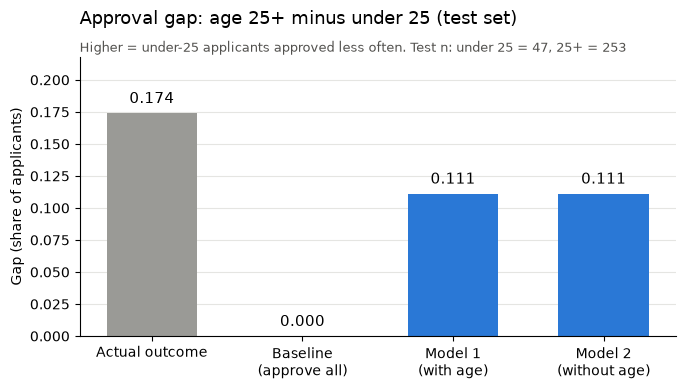

In [16]:
import matplotlib.pyplot as plt

# 10단계 표에서 gap만, 보여줄 순서대로
order = [
    "Actual (test 실제 good 비율)",
    "Baseline (전원 승인)",
    "Model 1 (LogReg, 나이 포함)",
    "Model 2 (LogReg, 나이 제외)",
]
gaps = final_comparison["gap"].loc[order]

labels = ["Actual outcome", "Baseline\n(approve all)", "Model 1\n(with age)", "Model 2\n(without age)"]
colors = ["#9a9a96", "#2a78d6", "#2a78d6", "#2a78d6"]   # 실제 = 회색, 모델 = 파란색

fig, ax = plt.subplots(figsize=(7, 4))
ax.bar(labels, gaps.values, color=colors, width=0.6)

# 막대 위에 숫자 쓰기
for i, v in enumerate(gaps.values):
    ax.text(i, v + 0.005, f"{v:.3f}", ha="center", va="bottom", fontsize=11)

ax.set_title("Approval gap: age 25+ minus under 25 (test set)", loc="left", fontsize=13, pad=24)
ax.text(0, 1.02, f"Higher = under-25 applicants approved less often. Test n: under 25 = {n_under25}, 25+ = {n_25plus}",
        transform=ax.transAxes, fontsize=9, color="#52514e")
ax.set_ylabel("Gap (share of applicants)")
ax.set_ylim(0, max(gaps.values) * 1.25)
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.grid(axis="y", color="#e5e5e2", linewidth=0.8)
ax.set_axisbelow(True)

fig.tight_layout()
fig.savefig("gap_chart.png", dpi=200)
plt.show()

## 15단계: 결론

### 질문 1. 대출 심사 모델이 25세 미만 신청자를 불리하게 대할까?
**승인율로 보면 그렇다.** 모델 1(나이 포함 logistic regression)은 test 세트에서
- 25세 이상의 **77.1%**, 25세 미만의 **66.0%**를 승인했다 → **gap 0.111 (약 11%p)**
- accuracy는 0.740으로, 전원 승인 베이스라인(0.700)보다 4%p 높다.

하지만 이 차이는 모델이 새로 만든 것이 아니다. **test 세트의 실제 상환 결과에도 이미 0.174(17%p)의 차이**가 있다 (실제 good 비율: 25세 이상 0.727, 25세 미만 0.553). 모델의 gap은 실제 차이보다 **작다**. 25세 미만을 실제 good 비율(55%)보다 더 많이(66%) 승인했다.

### 질문 2. 나이 컬럼을 빼도 그 차이가 남을까?
**남는다.** 모델 2(나이 제외)는
- accuracy 0.747, 그룹별 승인율과 **gap 0.111이 모델 1과 똑같다.**
- 300명 중 예측이 바뀐 사람은 4명뿐이고, 모두 25세 이상이다. 25세 미만 47명의 결정은 하나도 바뀌지 않았다.

### 왜 남을까? → 다른 변수에 나이가 숨어 있다 (대리 변수)
- `age`를 뺀 19개 변수만으로 "25세 미만인지"를 예측하는 모델이 test에서 **ROC AUC 0.836**을 냈다. 0.5(정보 없음)보다 한참 높다. 그러니까 나이 정보가 다른 변수에 많이 남아 있다.
- 나이를 가장 잘 드러내는 변수: 남성 이혼/별거, 관리직·자영업, 근무 7년 이상, 사업 목적 대출 (모두 나이 든 쪽의 특징), **월세/전세** (젊은 쪽의 특징)
- 이 중 **월세/전세**는 승인 모델에서도 승인을 꽤 낮추는 계수(−0.437)를 받았다. 그래서 나이 gap이 지나가는 대표적인 통로로 보인다. 나머지 4개는 승인 계수가 작다. 그래서 gap은 이 5개만이 아니라 **여러 변수에 나뉘어 퍼진 나이 정보** 때문일 가능성이 크다.

**핵심 메시지:** "나이 컬럼을 지우면 나이 차별이 사라진다"(*fairness through unawareness*)는 이 데이터에서 성립하지 않는다. 나이 gap을 줄이려면 컬럼을 지우는 것이 아니라, 그룹별 결과를 직접 재고 관리해야 한다.

### 한계 (발표 때 꼭 말할 것)
1. **표본이 작다.** test의 25세 미만은 47명뿐이다. 한 명이 바뀔 때마다 승인율이 약 2%p 움직인다. 그리고 train/test를 **한 번만** 나눠서 본 결과다 (`random_state=42`). 다른 split에서는 숫자가 조금 달라질 수 있다.
2. **공정성 기준을 하나만 봤다.** 승인율 차이(demographic parity)만 쟀다. "실제로 갚을 사람 중 승인된 비율"이 그룹별로 같은지(equal opportunity) 같은 다른 기준은 보지 않았다.
3. **정답(good/bad) 자체가 편향됐을 수 있다.** 라벨은 1994년에 공개된 독일 은행 데이터의 과거 결과다. 과거의 대출 조건이나 심사가 젊은 사람에게 불리했다면, 그 영향이 "정답"에 이미 들어 있을 수 있다.
4. **계수는 원인이 아니다.** 계수는 "함께 나타난다(상관)"를 보여줄 뿐이다. 그리고 같은 변수 안의 다른 코드와 비교한 상대값이다.
5. **데이터 한계:** `personal_status_sex`에 성별이 섞여 있고, 미혼 여성(A95)은 데이터에 없다. 모델은 튜닝 없이 기본 설정과 0.5 기준만 썼다.

# Phase 3: 비용 기준과 차이 줄이기

## 16단계: 비용 기준으로 승인 threshold 고르기 (train 세트, 교차검증)

**왜 비용을 따지나?** 지금까지 모델은 "good일 확률 > 0.5면 승인"이라는 기본 기준을 썼다. 하지만 은행에게 두 가지 실수의 손해는 다르다. 이 데이터셋의 원본 문서는 다음 **비용표(cost matrix)**를 쓰라고 한다.

| | 실제 good | 실제 bad |
|---|---|---|
| **승인** | 0 (맞음) | **5** (못 갚을 사람에게 빌려줌) |
| **거절** | **1** (갚을 사람을 놓침) | 0 (맞음) |

- 나쁜 신청자를 승인하면 돈을 떼이니까 비용 5, 좋은 신청자를 거절하면 이자 수익을 놓치니까 비용 1이다.
- **총비용 = 5 × (bad인데 승인한 수) + 1 × (good인데 거절한 수)**. 낮을수록 좋다.

**threshold(기준값)란?** 모델 2는 각 사람에게 "good일 확률"을 준다. **확률 ≥ threshold면 승인**한다. threshold를 올리면 더 확실한 사람만 승인해서 bad 승인(비용 5)은 줄지만, good 거절(비용 1)은 늘어난다. 총비용이 가장 낮은 지점을 찾는다.

**이론으로 미리 예상하기:** 확률이 p인 사람을 승인하면 기대 비용은 (1 − p) × 5, 거절하면 p × 1이다. 승인이 더 싸려면 (1 − p) × 5 < p, 즉 **p > 5/6 ≈ 0.83**이어야 한다. 그러니 0.5보다 훨씬 높은 threshold가 나올 것이다.

**test를 쓰지 않고 threshold를 고르는 방법: 교차검증 (5-fold)**
- train 700명을 5조각으로 나눈다. 4조각으로 모델 2를 학습하고, 남은 1조각의 확률을 예측한다. 이걸 5번 반복하면 **train의 모든 사람이 "자기를 학습에 쓰지 않은 모델"에게서 받은 확률**을 하나씩 갖게 된다.
- 학습에 쓴 사람을 그대로 평가하면 확률이 너무 자신만만하게 나온다. 그래서 이렇게 해야 처음 보는 사람에 가까운 확률로 threshold를 고를 수 있다.
- 이 확률로 threshold 0.01 ~ 0.99를 하나씩 시험해서 **train 총비용이 가장 낮은 값**을 고른다. **test는 전혀 쓰지 않는다.**

**코드 설명**
- `StratifiedKFold(n_splits=5, shuffle=True, random_state=42)`: good/bad 비율을 유지하면서 5조각으로 나누는 방법 (재현 가능하게 고정)
- `cross_val_predict(clone(model2), ..., method="predict_proba")`: 위의 5번 반복을 한 줄로 해준다. `clone`은 학습 전 상태의 모델 2 복사본이다. `[:, 1]`은 good일 확률만 꺼낸다.
- `total_cost(정답, 예측)`: 비용표대로 총비용을 계산하는 함수. `&`는 "그리고"라는 뜻이다.
- `thresholds = [i / 100 for i in range(1, 100)]`: 0.01, 0.02, …, 0.99
- `train_costs.idxmin()`: 총비용이 가장 작은 threshold

In [17]:
from sklearn.model_selection import StratifiedKFold, cross_val_predict

# 비용표: bad인데 승인 = 5, good인데 거절 = 1
def total_cost(y_true, y_pred):
    approve_bad = ((y_pred == 1) & (y_true == 0)).sum()
    reject_good = ((y_pred == 0) & (y_true == 1)).sum()
    return 5 * approve_bad + 1 * reject_good

# train 안에서 5-fold 교차검증으로 "처음 보는 사람" 같은 확률 만들기
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
train_prob = cross_val_predict(clone(model2), X_train_no_age, y_train, cv=cv, method="predict_proba")[:, 1]
train_prob = pd.Series(train_prob, index=X_train.index)

# threshold 0.01 ~ 0.99를 하나씩 시험해서 train 총비용 계산
thresholds = [i / 100 for i in range(1, 100)]
train_costs = pd.Series(
    [total_cost(y_train, (train_prob >= t).astype(int)) for t in thresholds],
    index=thresholds,
)

cost_threshold = train_costs.idxmin()
print("비용이 가장 낮은 threshold:", cost_threshold)          # 이론값 5/6 ≈ 0.83 근처
print("그때 train 총비용:", train_costs.min())
print("기본 threshold 0.5일 때 train 총비용:", train_costs[0.5])
print()
print("총비용이 낮은 threshold 상위 5개:")
print(train_costs.sort_values().head(5))

비용이 가장 낮은 threshold: 0.88
그때 train 총비용: 381
기본 threshold 0.5일 때 train 총비용: 647

총비용이 낮은 threshold 상위 5개:
0.88    381
0.85    382
0.86    382
0.82    384
0.84    385
dtype: int64


## 17단계: 비용 기준 threshold를 test 세트에 적용하기

16단계에서 train만 보고 고른 threshold(0.88)를 이제 처음으로 test에 적용한다. threshold는 이미 정해졌으니, test는 **평가에만** 쓰는 것이다.

**계산하는 것**
- **accuracy**: 맞은 비율
- **총비용**: 16단계와 같은 비용표 (bad 승인 = 5, good 거절 = 1). test 300명 기준이다.
- **그룹별 승인율과 gap**: 지금까지와 같다.
- **그룹별 "좋은 신청자 승인율"**: **실제로 good인 사람 중에서** 승인된 비율이다. 3번(차이 줄이기)에서 이 값을 두 그룹에서 비슷하게 맞출 것이라 미리 같이 본다.
  - 정식 이름은 **true positive rate (TPR)**이다. 이 값이 두 그룹에서 같으면 "**equal opportunity**(갚을 능력이 있는 사람은 나이와 상관없이 같은 확률로 승인)"라고 부른다.

**코드 설명**
- `model2.predict_proba(X_test_no_age)[:, 1]`: test 사람마다 good일 확률. 모델 2는 다시 학습하지 않고 그대로 쓴다.
- `(test_prob >= cost_threshold).astype(int)`: 확률이 0.88 이상이면 1(승인), 아니면 0(거절)
- `evaluate(예측)`: 위 지표들을 한 번에 계산해서 딕셔너리로 돌려주는 함수다. 다음 단계에서도 같은 함수를 다시 쓴다.
  - `y_test == 1`: 실제 good인 사람만 고르는 True/False 줄
  - `pred[good].groupby(group_test[good]).mean()`: 실제 good인 사람들 안에서 그룹별 승인율 = 그룹별 좋은 신청자 승인율
- 비교를 위해 기본 모델 2(threshold 0.5)도 같은 함수로 계산해서 나란히 출력한다.

In [18]:
def evaluate(pred):
    """test 세트에서 예측(1 = 승인, 0 = 거절)의 지표를 계산한다."""
    rates = pred.groupby(group_test).mean()               # 그룹별 승인율
    good = y_test == 1                                     # 실제 good인 사람
    good_rates = pred[good].groupby(group_test[good]).mean()   # 그룹별 좋은 신청자 승인율
    return {
        "accuracy": accuracy_score(y_test, pred),
        "total_cost": total_cost(y_test, pred),
        "approval_under25": rates["under 25"],
        "approval_25plus": rates["25+"],
        "good_approval_under25": good_rates["under 25"],
        "good_approval_25plus": good_rates["25+"],
        "gap": rates["25+"] - rates["under 25"],
    }

# 모델 2가 test 사람마다 준 good일 확률 (다시 학습하지 않음)
test_prob = pd.Series(model2.predict_proba(X_test_no_age)[:, 1], index=X_test.index)

# 비용 기준 threshold로 승인/거절
cost_pred = (test_prob >= cost_threshold).astype(int)

result_default = evaluate(model2_pred)   # 기본 (threshold 0.5)
result_cost = evaluate(cost_pred)        # 비용 기준 (threshold 0.88)

pd.DataFrame(
    {"Model 2 (기본, 0.5)": result_default, f"Model 2 + 비용 기준 ({cost_threshold})": result_cost}
).round(3)

,"Model 2 (기본, 0.5)",Model 2 + 비용 기준 (0.88)
accuracy,0.747,0.583
total_cost,260.000,161.000
approval_under25,0.660,0.191
approval_25plus,0.771,0.372
good_approval_under25,0.731,0.308
good_approval_25plus,0.875,0.467
gap,0.111,0.180


## 18단계: 차이 줄이기 — 25세 미만 그룹의 threshold만 따로 정하기 (train 세트)

17단계에서 비용 기준(0.88)을 쓰니까, 갚을 능력이 있는(good) 25세 미만은 31%만 승인됐다. 같은 조건의 25세 이상은 47%였다. 이 차이를 줄여 본다.

**목표: equal opportunity (기회의 평등)**
- **실제로 good인 사람 중 승인되는 비율**(좋은 신청자 승인율)을 두 그룹에서 비슷하게 만든다.
- 뜻: "갚을 능력이 있다면, 나이와 상관없이 비슷한 확률로 승인받아야 한다."

**방법**
1. **25세 이상은 그대로 둔다:** threshold 0.88 (16단계의 비용 기준)
2. train에서 25세 이상의 좋은 신청자 승인율을 잰다 → 이게 **목표값**이다.
3. **25세 미만의 threshold만** 0.01 ~ 0.99로 바꿔 보면서, 25세 미만의 좋은 신청자 승인율이 목표값에 **가장 가까운** threshold를 고른다.

**test를 쓰지 않는다.** 16단계와 같은 train 교차검증 확률(`train_prob`)만 쓴다. 학습에 쓴 사람의 확률은 너무 자신만만해서 기준을 정하기에 좋지 않기 때문이다.

**주의: 이 방법은 나이를 직접 쓴다.** 승인 기준이 나이 그룹마다 다르다. 모델 입력에서는 나이를 뺐지만, 결정 단계에서 다시 나이를 쓰는 셈이다. 현실의 대출 심사에서는 법이나 규정상 문제가 될 수 있다. 이 점은 write-up에서 따로 논의한다.

**작은 표본 주의:** train의 25세 미만은 102명이고, 그중 good은 62명뿐이다. 그래서 고른 threshold는 꽤 흔들릴 수 있다.

**코드 설명**
- `group_train = group.loc[X_train.index]`: train 사람들의 나이 그룹 (5단계의 `group_test`와 같은 방법)
- `old_good`, `young_good`: train에서 "25세 이상이면서 good", "25세 미만이면서 good"인 사람을 고르는 True/False 줄
- `(train_prob[old_good] >= cost_threshold).mean()`: 25세 이상 좋은 신청자 중 승인 비율 = 목표값
- `abs(...)`: 목표값과의 차이 (절댓값). `.idxmin()`으로 차이가 가장 작은 threshold를 고른다.

In [19]:
# train 사람들의 나이 그룹
group_train = group.loc[X_train.index]

old_good = (group_train == "25+") & (y_train == 1)         # 25세 이상이면서 good
young_good = (group_train == "under 25") & (y_train == 1)  # 25세 미만이면서 good
print("train good 인원: 25+ =", old_good.sum(), "/ under 25 =", young_good.sum())

# 목표값: 25세 이상(threshold 0.88)의 좋은 신청자 승인율 (train 교차검증 확률 기준)
target_rate = (train_prob[old_good] >= cost_threshold).mean()
print("목표 (25+ 좋은 신청자 승인율, train):", round(target_rate, 3))

# 25세 미만 threshold를 바꿔 보며 목표값과의 차이 계산
diff = pd.Series(
    [abs((train_prob[young_good] >= t).mean() - target_rate) for t in thresholds],
    index=thresholds,
)
young_threshold = diff.idxmin()
young_rate = (train_prob[young_good] >= young_threshold).mean()

print()
print("25세 미만 threshold:", young_threshold, " (25세 이상은 그대로", cost_threshold, ")")
print("그때 25세 미만 좋은 신청자 승인율 (train):", round(young_rate, 3))

train good 인원: 25+ = 428 / under 25 = 62
목표 (25+ 좋은 신청자 승인율, train): 0.474

25세 미만 threshold: 0.83  (25세 이상은 그대로 0.88 )
그때 25세 미만 좋은 신청자 승인율 (train): 0.468


## 19단계: 비교표 — 기본 / 비용 기준 / 차이 줄이기 (test 세트)

18단계에서 train으로 정한 두 threshold를 test에 적용한다. 그리고 세 가지 방식을 한 표에서 비교한다.

| 방식 | 25세 이상 threshold | 25세 미만 threshold |
|---|---|---|
| Model 2 (기본) | 0.5 | 0.5 |
| Model 2 + 비용 기준 | 0.88 | 0.88 |
| Model 2 + 차이 줄이기 | 0.88 | **0.83** |

**표의 행 (모두 test 300명 기준)**
- `accuracy`, `total_cost`: 맞은 비율, 비용표 총비용 (bad 승인 = 5, good 거절 = 1)
- `approval_under25`, `approval_25plus`: 그룹별 승인율
- `good_approval_under25`, `good_approval_25plus`: 그룹별 **좋은 신청자 승인율** (실제 good 중 승인된 비율)
- `gap`: 승인율 차이 (25+ − under 25)
- `good_approval_gap`: 좋은 신청자 승인율 차이 (25+ − under 25). 차이 줄이기가 **직접 맞추려고 한 값**이라 같이 본다.

**읽을 때 주의:** test에서 좋은 신청자 중 25세 미만은 26명뿐이다. 그래서 그 승인율은 한 명당 약 4%p씩 움직인다.

**코드 설명**
- `group_test == "under 25"`: test 사람마다 25세 미만이면 True
- `[young_threshold if g == "under 25" else cost_threshold for g in group_test]`: test 사람을 한 명씩 보면서, 25세 미만이면 `young_threshold`, 아니면 `cost_threshold`를 고른다 → 사람마다 자기 threshold
- `test_prob >= person_threshold`: 사람마다 자기 threshold와 비교해서 승인/거절
- `evaluate(...)`: 17단계에서 만든 함수를 그대로 쓴다.
- `pd.DataFrame({이름: 결과, ...})`: 결과 딕셔너리 3개를 열 3개짜리 표로 만든다.

In [20]:
# 사람마다 자기 그룹의 threshold: 25세 미만 = young_threshold, 25세 이상 = cost_threshold
person_threshold = pd.Series(
    [young_threshold if g == "under 25" else cost_threshold for g in group_test],
    index=X_test.index,
)
fair_pred = (test_prob >= person_threshold).astype(int)

result_fair = evaluate(fair_pred)

phase3_table = pd.DataFrame({
    "Model 2 (기본)": result_default,
    "Model 2 + 비용 기준": result_cost,
    "Model 2 + 차이 줄이기": result_fair,
})

# 좋은 신청자 승인율 차이 (차이 줄이기가 맞추려고 한 값)
phase3_table.loc["good_approval_gap"] = (
    phase3_table.loc["good_approval_25plus"] - phase3_table.loc["good_approval_under25"]
)

print("test 좋은 신청자 인원: under 25 =", ((group_test == "under 25") & (y_test == 1)).sum(),
      "/ 25+ =", ((group_test == "25+") & (y_test == 1)).sum())
phase3_table.round(3)

test 좋은 신청자 인원: under 25 = 26 / 25+ = 184


,Model 2 (기본),Model 2 + 비용 기준,Model 2 + 차이 줄이기
accuracy,0.747,0.583,0.593
total_cost,260.000,161.000,158.000
approval_under25,0.660,0.191,0.255
approval_25plus,0.771,0.372,0.372
good_approval_under25,0.731,0.308,0.423
good_approval_25plus,0.875,0.467,0.467
gap,0.111,0.180,0.116
good_approval_gap,0.144,0.160,0.044


## 20단계: 그룹별 승인율 막대그래프 (발표용)

19단계 표의 그룹별 승인율을 방식마다 나란히 그린다. 한 방식에 막대 2개(25세 미만, 25세 이상)가 붙어 있어서, 두 막대의 높이 차이가 곧 gap이다.

**그래프 설계**
- **주황 = 25세 미만, 파랑 = 25세 이상.** 이 두 색은 색맹인 사람도 구분할 수 있는지 검사를 통과했다. 범례도 함께 둔다.
- 막대 위에 승인율 숫자를 적고, 각 방식 이름 아래에 gap을 적는다.
- 14단계처럼 글자는 영어로 쓴다 (한글 폰트 문제).

**코드 설명**
- `x = list(range(3))`: 방식 3개의 위치 0, 1, 2
- `[i - width / 2 for i in x]`, `[i + width / 2 for i in x]`: 같은 위치에서 왼쪽(25세 미만)과 오른쪽(25세 이상)으로 반 칸씩 비켜서 막대를 나란히 놓는다.
- `ax.bar(위치, 값, width, label=이름, color=색)`: 막대 묶음 하나를 그린다. `label`은 범례에 쓰인다. `edgecolor="white"`는 붙어 있는 두 막대 사이에 얇은 흰 틈을 만든다.
- `names`의 threshold 숫자는 직접 쓰지 않고 `cost_threshold`, `young_threshold` 변수에서 가져온다. 그래야 앞 단계 결과가 바뀌어도 그래프가 맞게 따라간다.
- `ax.text(...)`: 막대 위에 숫자를 쓴다.
- `ax.set_xticks(x, 이름표)`: 방식 이름(과 gap)을 x축에 쓴다.
- `fig.savefig("approval_rates_chart.png", dpi=200)`: 슬라이드용 PNG로 저장한다.

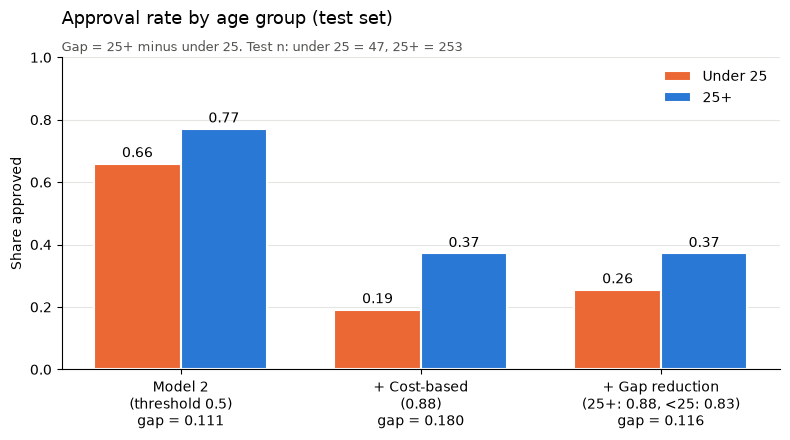

In [21]:
methods = ["Model 2 (기본)", "Model 2 + 비용 기준", "Model 2 + 차이 줄이기"]
names = [
    "Model 2\n(threshold 0.5)",
    f"+ Cost-based\n({cost_threshold})",
    f"+ Gap reduction\n(25+: {cost_threshold}, <25: {young_threshold})",
]

under = phase3_table.loc["approval_under25", methods].values
older = phase3_table.loc["approval_25plus", methods].values
gaps = phase3_table.loc["gap", methods].values

x = list(range(3))
width = 0.36

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.bar([i - width / 2 for i in x], under, width, label="Under 25", color="#eb6834", edgecolor="white", linewidth=1.5)
ax.bar([i + width / 2 for i in x], older, width, label="25+", color="#2a78d6", edgecolor="white", linewidth=1.5)

# 막대 위에 승인율 숫자
for i in x:
    ax.text(i - width / 2, under[i] + 0.01, f"{under[i]:.2f}", ha="center", va="bottom", fontsize=10)
    ax.text(i + width / 2, older[i] + 0.01, f"{older[i]:.2f}", ha="center", va="bottom", fontsize=10)

# x축: 방식 이름 + gap
ax.set_xticks(x, [f"{n}\ngap = {g:.3f}" for n, g in zip(names, gaps)])

ax.set_title("Approval rate by age group (test set)", loc="left", fontsize=13, pad=24)
ax.text(0, 1.02, f"Gap = 25+ minus under 25. Test n: under 25 = {n_under25}, 25+ = {n_25plus}",
        transform=ax.transAxes, fontsize=9, color="#52514e")
ax.set_ylabel("Share approved")
ax.set_ylim(0, 1)
ax.legend(frameon=False, loc="upper right")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.grid(axis="y", color="#e5e5e2", linewidth=0.8)
ax.set_axisbelow(True)

fig.tight_layout()
fig.savefig("approval_rates_chart.png", dpi=200)
plt.show()

# Phase 4: 실패 분석과 데모

## 21단계: 좋은 신청자인데 거절된 25세 미만 (test 세트)

**기준:** 모델 2 + 비용 기준 (threshold 0.88, 17단계의 `cost_pred`). 은행이 실제로 쓸 법한 기준이라 이걸로 본다.

**누구를 보나?** test에서 다음 세 조건을 모두 만족하는 사람
1. 25세 미만
2. 실제로 **good** (갚았음)
3. 모델이 **거절**함 → 은행 입장에서는 "놓친 좋은 고객", 신청자 입장에서는 "억울한 거절"이다.

19단계 표에서 25세 미만 좋은 신청자의 승인율이 0.308이었다. 그러니까 26명 중 18명이 여기에 해당한다.

**보여주는 변수 (주요 변수만)**
- `good_prob`: 모델 2가 준 good일 확률. 0.88보다 낮아서 거절됐다. 높은 순서로 정렬하면 **아깝게 떨어진 사람**이 위에 온다.
- `age`, `duration_months`, `credit_amount`: 나이, 대출 기간(개월), 대출 금액(DM)
- `checking_status`, `credit_history`, `savings`, `employment_since`, `housing`, `purpose`: 2-2단계 `code_table`의 한국어 뜻으로 바꿔서 보여준다.
- `이유`: **빈칸.** 각 사람이 왜 거절됐을지는 직접 보고 채운다. (다음 단계의 함수가 모델 입장의 이유를 계산해 준다.)

**코드 설명**
- `mask = (group_test == "under 25") & (y_test == 1) & (cost_pred == 0)`: 세 조건을 `&`(그리고)로 묶은 True/False 줄
- `X_test.loc[mask, 보여줄 컬럼]`: 조건에 맞는 사람의 주요 변수만 꺼낸다. `.copy()`는 원본 `X_test`를 건드리지 않으려고 복사하는 것이다.
- `code_to_ko`: 코드 → 한국어 뜻 사전. `A11` 같은 코드는 컬럼마다 겹치지 않아서 사전 하나로 충분하다.
- `.replace(code_to_ko)`: 표 안의 코드를 한국어 뜻으로 바꾼다.
- `.sort_values("good_prob", ascending=False)`: 확률이 높은 순서로 정렬한다.

In [22]:
# 25세 미만 + 실제 good + 비용 기준에서 거절
mask = (group_test == "under 25") & (y_test == 1) & (cost_pred == 0)
print("좋은 신청자인데 거절된 25세 미만:", mask.sum(), "명 /",
      ((group_test == "under 25") & (y_test == 1)).sum(), "명")

show_cols = [
    "age", "duration_months", "credit_amount", "checking_status",
    "credit_history", "savings", "employment_since", "housing", "purpose",
]

rejected_young = X_test.loc[mask, show_cols].copy()

# 코드(A11 등) → 한국어 뜻
code_to_ko = dict(zip(code_table["code"], code_table["뜻"]))
rejected_young = rejected_young.replace(code_to_ko)

# 모델 2가 준 good일 확률 (0.88 미만이라 거절됨)
rejected_young.insert(0, "good_prob", test_prob[mask].round(3))

# 이유는 직접 채울 빈칸
rejected_young["이유"] = ""

rejected_young.sort_values("good_prob", ascending=False)

좋은 신청자인데 거절된 25세 미만: 18 명 / 26 명


,good_prob,age,duration_months,credit_amount,checking_status,credit_history,savings,employment_since,housing,purpose,이유
480,0.877,23,12,3573,잔고 0 이상 200 DM 미만,위험 계좌 / 다른 은행에 대출 있음,100 DM 미만,1년 이상 4년 미만,자가,라디오/TV,
391,0.866,19,12,983,잔고 0 이상 200 DM 미만,현재 대출을 지금까지 제때 상환 중,1000 DM 이상,1년 미만,월세/전세,가구/장비,
122,0.845,24,12,1768,당좌 계좌 없음,현재 대출을 지금까지 제때 상환 중,100 DM 미만,1년 이상 4년 미만,월세/전세,가구/장비,
217,0.824,23,36,3913,잔고 200 DM 이상 또는 1년 이상 급여 이체,현재 대출을 지금까지 제때 상환 중,100 DM 미만,1년 이상 4년 미만,자가,라디오/TV,
67,0.770,22,12,1007,잔고 0 이상 200 DM 미만,현재 대출을 지금까지 제때 상환 중,1000 DM 이상,1년 이상 4년 미만,자가,새 차,
752,0.770,23,12,841,잔고 0 이상 200 DM 미만,현재 대출을 지금까지 제때 상환 중,100 이상 500 DM 미만,4년 이상 7년 미만,월세/전세,사업,
82,0.747,24,18,1568,당좌 계좌 없음,현재 대출을 지금까지 제때 상환 중,100 이상 500 DM 미만,1년 이상 4년 미만,월세/전세,사업,
134,0.724,21,60,10144,당좌 계좌 없음,현재 대출을 지금까지 제때 상환 중,100 이상 500 DM 미만,4년 이상 7년 미만,자가,라디오/TV,
802,0.633,24,20,4272,잔고 0 DM 미만 (마이너스),위험 계좌 / 다른 은행에 대출 있음,100 DM 미만,7년 이상,자가,가구/장비,
152,0.598,24,36,5848,잔고 200 DM 이상 또는 1년 이상 급여 이체,현재 대출을 지금까지 제때 상환 중,100 DM 미만,1년 이상 4년 미만,자가,라디오/TV,


## 22단계: 신청자 한 명을 설명하는 함수

신청자 한 명의 정보를 넣으면 다음을 돌려주는 함수 `explain_applicant`를 만든다.
1. **결정**: 승인 / 거절 (모델 2 + 비용 기준 threshold 0.88)
2. **승인 확률**: 모델 2가 준 good일 확률
3. **이유 3개**: 결정에 가장 크게 작용한 입력 3개

### "이유"를 계산하는 방법: 계수 × 값
Logistic regression은 점수를 이렇게 만든다.

> **점수 = 절편 + (계수₁ × 값₁) + (계수₂ × 값₂) + …**, 그리고 확률 = 점수를 0~1로 바꾼 값

그래서 **계수 × 값** 하나하나가 그 입력이 점수를 얼마나 올렸는지(+) 또는 내렸는지(−)를 보여준다.
- **범주형 (one-hot)**: 이 사람에게 해당하는 코드만 값이 1이고 나머지는 0이다. 그래서 해당 코드의 계수가 그대로 기여도가 된다. 예: 월세/전세면 `housing_A151`의 계수
- **숫자형 (스케일링됨)**: 값은 "평균에서 표준편차 몇 개만큼 떨어졌나"이다. 평균보다 크면 +, 작으면 −. 그래서 대출 기간처럼 계수가 음수인 변수는, 평균보다 **길면** 점수를 내리고 **짧으면** 점수를 올린다.

**어떤 3개를 고르나?**
- **거절**이면 점수를 **가장 많이 내린** 3개 (기여도가 가장 작은 음수)
- **승인**이면 점수를 **가장 많이 올린** 3개 (기여도가 가장 큰 양수)
- 즉 "결정을 그쪽으로 민 가장 큰 이유"를 보여준다.

**주의:** 범주형 계수는 같은 변수 안의 다른 코드와 비교한 상대값이다 (12단계와 같다). 그래서 "이유"는 "이 모델이 이 사람을 이렇게 봤다"는 설명이지, 현실의 원인을 증명하는 것은 아니다.

### 코드 설명
- `applicant`: 신청자 한 명. `X`와 같은 컬럼을 가진 **행 1개짜리 DataFrame**이다. `age`가 있어도 된다. 모델 2는 `age`를 안 쓰니까 `drop(columns="age", errors="ignore")`로 뺀다. `errors="ignore"`는 `age`가 없어도 에러를 내지 말라는 뜻이다.
- `pre.transform(row)`: 모델 2의 전처리(one-hot + 스케일링)를 그대로 적용한다. 결과가 sparse 행렬(0이 많을 때 0을 생략하고 저장하는 형식)이면 `.toarray()`로 보통 배열로 바꾼다.
- `coef * values`: 입력마다 계수 × 값 = 기여도
- `readable(name)`: `cat__housing_A151` 같은 이름을 `housing = 월세/전세`처럼 읽기 쉽게 바꾼다. 숫자형은 실제 값을 같이 보여준다.
- `.sort_values()`: 기여도를 작은 순서로 정렬한다. 거절이면 앞에서 3개(`head`), 승인이면 뒤에서 3개(`tail`)를 거꾸로 가져온다.
- `float(...)`: numpy 숫자를 보통 파이썬 숫자로 바꾼다. 그래야 출력이 `np.float64(0.877)`이 아니라 `0.877`로 깔끔하게 나온다.

In [24]:
def explain_applicant(applicant):
    """신청자 1명(행 1개짜리 DataFrame) → 결정, 승인 확률, 이유 3개 (모델 2 + 비용 기준)."""
    row = applicant.drop(columns="age", errors="ignore")   # 모델 2는 age를 쓰지 않음

    # 1) 승인 확률과 결정
    prob = model2.predict_proba(row)[0, 1]
    decision = "승인" if prob >= cost_threshold else "거절"

    # 2) 입력마다 계수 × 값 = 기여도
    pre = model2.named_steps["preprocess"]
    values = pre.transform(row)
    if hasattr(values, "toarray"):        # sparse 행렬이면 보통 배열로
        values = values.toarray()
    coef = model2.named_steps["logreg"].coef_[0]
    contrib = pd.Series(coef * values[0], index=pre.get_feature_names_out())

    # 3) 읽기 쉬운 이름: "cat__housing_A151" → "housing = 월세/전세"
    def readable(name):
        kind, rest = name.split("__")
        if kind == "num":
            return f"{rest} = {row[rest].iloc[0]}"
        col, code = rest.rsplit("_", 1)
        return f"{col} = {code_to_ko.get(code, code)}"

    # 4) 결정 쪽으로 가장 크게 민 3개
    ordered = contrib.sort_values()
    top3 = ordered.head(3) if decision == "거절" else ordered.tail(3)[::-1]
    reasons = [(readable(name), round(float(value), 3)) for name, value in top3.items()]

    return {"결정": decision, "승인 확률": round(float(prob), 3), "이유": reasons}


# 예시 1: 21단계 표 맨 위 (아깝게 거절된 23세)
print("예시 1 (test 480번):")
print(explain_applicant(X_test.loc[[480]]))
print()

# 예시 2: 승인된 사람 중 한 명
approved_id = cost_pred[cost_pred == 1].index[0]
print(f"예시 2 (test {approved_id}번):")
print(explain_applicant(X_test.loc[[approved_id]]))

예시 1 (test 480번):
{'결정': '거절', '승인 확률': 0.877, '이유': [('savings = 100 DM 미만', -0.726), ('foreign_worker = 외국인 노동자 예', -0.598), ('checking_status = 잔고 0 이상 200 DM 미만', -0.347)]}

예시 2 (test 80번):
{'결정': '승인', '승인 확률': 0.939, '이유': [('checking_status = 당좌 계좌 없음', 0.812), ('other_installment_plans = 없음', 0.446), ('installment_rate = 1', 0.414)]}


## 23단계: 나이만 30세로 바꾸면 결과가 바뀔까? (모델 1)

**질문:** 다른 정보는 모두 그대로 두고 **나이만** 30세로 바꾸면, 승인/거절이 달라질까?
이런 "만약 ~였다면?" 비교를 **반사실(counterfactual) 테스트**라고 한다. 결과가 바뀐다면, 모델이 **나이 그 자체** 때문에 결정을 바꾼다는 뜻이다.

**왜 모델 1인가?** 모델 2는 `age`를 입력으로 받지 않는다. 그래서 나이를 바꿔도 결과가 절대 안 바뀐다. 나이를 직접 쓰는 **모델 1**(7단계)이라야 이 테스트가 의미가 있다.
- 모델 1은 7단계처럼 기본 기준 **0.5**로 결정한다.

**이 테스트가 보여주지 못하는 것:** 나이를 바꿔도 근무 기간, 주거 형태 같은 **대리 변수는 그대로**다. 그래서 이 테스트는 "나이 컬럼의 **직접** 효과"만 잰다. 11~13단계에서 본 대리 변수를 통한 **간접** 효과는 잡지 못한다.

**코드 설명**
- `age_counterfactual(applicant, new_age=30)`: 신청자 1명을 받아서 원래 나이와 바꾼 나이일 때의 확률과 결정을 돌려준다. `new_age=30`은 따로 안 넣으면 30을 쓴다는 뜻이다.
- `changed = applicant.copy()`, `changed["age"] = new_age`: 복사본을 만들어 나이만 바꾼다. 원본은 그대로 둔다.
- `model1.predict_proba(...)[0, 1]`: 모델 1이 준 good일 확률
- 함수 아래에서는 test의 **25세 미만 47명 전체**에 같은 테스트를 해서, 결정이 바뀐 사람 수와 확률이 평균 얼마나 변했는지 센다.

In [ ]:
def age_counterfactual(applicant, new_age=30):
    """신청자 1명의 나이만 new_age로 바꿨을 때 모델 1(0.5 기준)의 결과 비교."""
    changed = applicant.copy()
    changed["age"] = new_age

    prob_before = model1.predict_proba(applicant)[0, 1]
    prob_after = model1.predict_proba(changed)[0, 1]
    decision_before = "승인" if prob_before > 0.5 else "거절"
    decision_after = "승인" if prob_after > 0.5 else "거절"

    return {
        "원래 나이": int(applicant["age"].iloc[0]),
        "원래 확률": round(float(prob_before), 3),
        "원래 결정": decision_before,
        f"{new_age}세 확률": round(float(prob_after), 3),
        f"{new_age}세 결정": decision_after,
        "결정이 바뀜": decision_before != decision_after,
    }


# 예시: 22단계의 test 480번 (23세)
print("예시 (test 480번):")
print(age_counterfactual(X_test.loc[[480]]))
print()

# test의 25세 미만 47명 전체에 같은 테스트
young_ids = X_test.index[group_test == "under 25"]
results = pd.DataFrame([age_counterfactual(X_test.loc[[i]]) for i in young_ids], index=young_ids)

print("test 25세 미만", len(results), "명 중 30세로 바꿨을 때 결정이 바뀐 사람:", results["결정이 바뀜"].sum(), "명")
print("승인 확률 평균 변화:", round((results["30세 확률"] - results["원래 확률"]).mean(), 3))